# Business cycles: the wiggles

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mhaabeth/Econ-4310/blob/main/business_cycles.ipynb)

ECON4310, University of Oslo.

This notebook
1. downloads quarterly national accounts for Mainland Norway from Statistics Norway (SSB),
2. separates trend from cycle with the Hodrick–Prescott filter and the Hamilton (2018) filter,
3. computes the standard business cycle facts for output, consumption and investment,
4. fits an AR(1) to the cycle and simulates it.

Data: SSB table [09190](https://www.ssb.no/en/statbank/table/09190), constant 2023 prices, seasonally adjusted, NOK million.

In [4]:
# Setup for Google Colab: fetch the course files (helper code and data). Does nothing elsewhere.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("ssb.py"):
    os.system("git clone -q https://github.com/mhaabeth/Econ-4310.git")
    os.chdir("Econ-4310")

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.filters.hp_filter import hpfilter

from ssb import get_quarterly, load_snapshot

plt.rcParams.update({
    "figure.figsize": (7, 3.8),
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
})
BLUE, RED, GREY = "#1f4e9c", "#c0392b", "#7f7f7f"


## 1. Data

`Makrost` codes in table 09190:

| Code | Series |
|---|---|
| `bnpb.nr23_9fn` | GDP Mainland Norway, market values |
| `koh.nrpriv` | Final consumption of households and NPISHs |
| `bif.nr83_6fn` | Gross fixed capital formation, Mainland Norway |

The cell tries the live API first. If you are offline, it falls back to the snapshot in `data/`.

In [6]:
codes = {"bnpb.nr23_9fn": "Y", "koh.nrpriv": "C", "bif.nr83_6fn": "I"}

try:
    raw = get_quarterly("09190", {"Makrost": list(codes),
                                  "ContentsCode": ["FastePriserSesJust"]})
    source = "SSB API"
except Exception as err:
    raw = load_snapshot()
    source = f"snapshot (API unavailable: {type(err).__name__})"

df = raw.rename(columns=codes)[["Y", "C", "I"]]
print(f"Source: {source}. Sample: {df.index[0]} to {df.index[-1]}, {len(df)} quarters.")
df.tail()

Source: SSB API. Sample: 1978Q1 to 2026Q2, 194 quarters.


,Y,C,I
Tid,,,
2025Q2,1031316.0,546091.0,229177.0
2025Q3,1032673.0,552860.0,226663.0
2025Q4,1034254.0,557316.0,240850.0
2026Q1,1035398.0,550397.0,226805.0
2026Q2,1038794.0,549148.0,233413.0


In [7]:
# Work with 100 x log levels, so differences are (approximately) percent
logs = 100 * np.log(df)
t = logs.index.to_timestamp()

## 2. Trend and cycle: the HP filter

The HP trend $\tau_t$ solves

$$\min_{\{\tau_t\}} \sum_t (y_t - \tau_t)^2 + \lambda \sum_t \left[(\tau_{t+1}-\tau_t) - (\tau_t - \tau_{t-1})\right]^2 .$$

The cycle is $y_t - \tau_t$. The convention for quarterly data is $\lambda = 1600$.

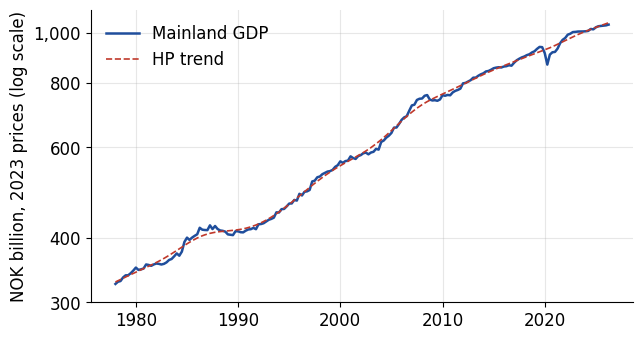

In [8]:
cycle = {}
trend = {}
for v in ["Y", "C", "I"]:
    cycle[v], trend[v] = hpfilter(logs[v], lamb=1600)
cycle = pd.DataFrame(cycle)
trend = pd.DataFrame(trend)

fig, ax = plt.subplots()
ax.plot(t, df["Y"] / 1000, color=BLUE, lw=1.8, label="Mainland GDP")
ax.plot(t, np.exp(trend["Y"] / 100) / 1000, color=RED, lw=1.2, ls="--", label="HP trend")
ax.set_yscale("log")
ax.set_yticks([300, 400, 600, 800, 1000])
ax.set_yticklabels(["300", "400", "600", "800", "1,000"])
ax.minorticks_off()
ax.set_ylabel("NOK billion, 2023 prices (log scale)")
ax.legend(frameon=False)
fig.savefig("figures/gdp.pdf")
plt.show()

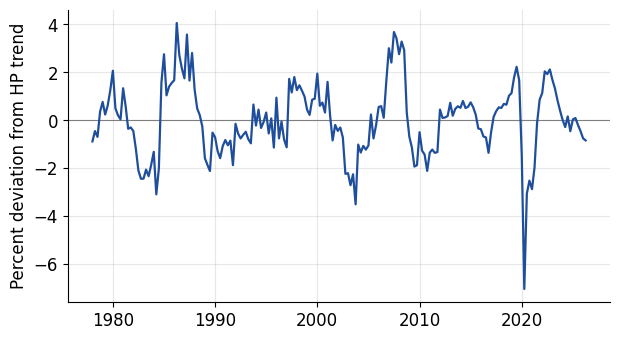

In [9]:
fig, ax = plt.subplots()
ax.axhline(0, color=GREY, lw=0.8)
ax.plot(t, cycle["Y"], color=BLUE, lw=1.6)
ax.set_ylabel("Percent deviation from HP trend")
fig.savefig("figures/gdp_cycle.pdf")
plt.show()

### The choice of $\lambda$ is a choice

$\lambda \to 0$ makes the trend equal to the data. $\lambda \to \infty$ makes it a straight line. Nothing in the data pins down $\lambda$.

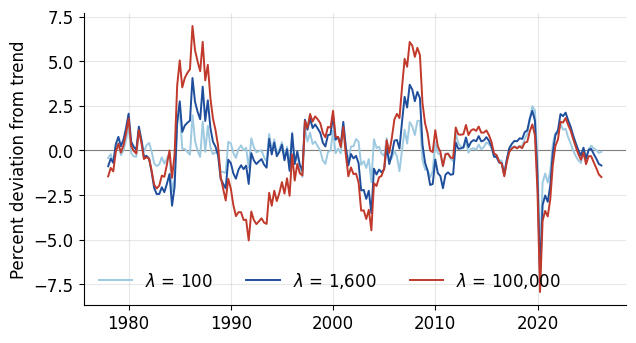

In [10]:
fig, ax = plt.subplots()
ax.axhline(0, color=GREY, lw=0.8)
for lam, c in [(100, "#9ecae1"), (1600, BLUE), (100_000, RED)]:
    ax.plot(t, hpfilter(logs["Y"], lamb=lam)[0], color=c, lw=1.4, label=f"$\\lambda$ = {lam:,}")
ax.set_ylabel("Percent deviation from trend")
ax.legend(frameon=False, ncol=3)
fig.savefig("figures/hp_lambda.pdf")
plt.show()

### 3. Business cycle facts

For each series: volatility of the cycle, volatility relative to output, correlation with the output cycle, and first-order autocorrelation. Compare with Kydland and Prescott (1990) for the US.

COVID-19 dominates the post-2020 sample, so the table reports both the full sample and the sample up to 2019Q4.

In [11]:
def bc_facts(c):
    sd = c.std()
    return pd.DataFrame({
        "Std. dev. (%)": sd,
        "Relative to Y": sd / sd["Y"],
        "Corr. with Y": c.corrwith(c["Y"]),
        "Autocorr.": c.apply(lambda s: s.autocorr(1)),
    }).round(2)

names = {"Y": "Output", "C": "Consumption", "I": "Investment"}
pre = cycle.index <= pd.Period("2019Q4", freq="Q")

print("HP filter, full sample")
display(bc_facts(cycle).rename(index=names))
print("HP filter, 1978-2019")
display(bc_facts(cycle[pre]).rename(index=names))

HP filter, full sample


,Std. dev. (%),Relative to Y,Corr. with Y,Autocorr.
Output,1.52,1.00,1.00,0.77
Consumption,1.98,1.30,0.79,0.66
Investment,5.18,3.39,0.54,0.57


HP filter, 1978-2019


,Std. dev. (%),Relative to Y,Corr. with Y,Autocorr.
Output,1.44,1.00,1.00,0.80
Consumption,1.64,1.13,0.75,0.78
Investment,5.48,3.80,0.61,0.58


## 4. Can an AR(1) produce wiggles like these?

Slutsky (1937) showed that summing random shocks produces series that look like cycles. Fit

$$\hat y_t = \rho \hat y_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim N(0, \sigma^2)$$

to the HP cycle in output, then simulate a series of the same length.

rho = 0.80, sigma = 0.86


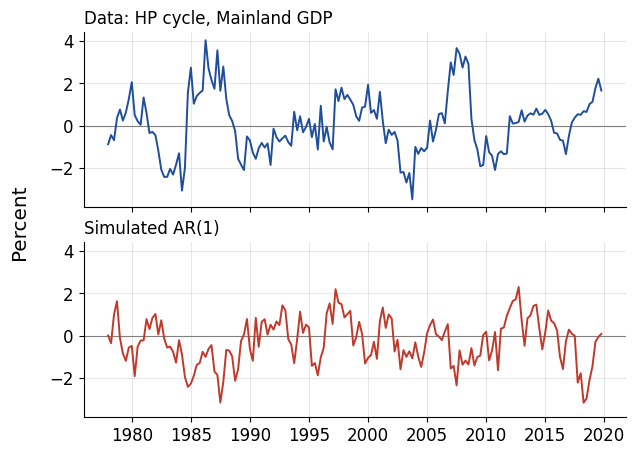

In [12]:
y = cycle["Y"][pre]
rho = y.autocorr(1)
sigma = (y - rho * y.shift(1)).dropna().std()
print(f"rho = {rho:.2f}, sigma = {sigma:.2f}")

rng = np.random.default_rng(4310)
sim = np.zeros(len(y))
for i in range(1, len(y)):
    sim[i] = rho * sim[i - 1] + sigma * rng.standard_normal()

fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True, sharey=True)
for ax, series, label, c in [(axes[0], y.values, "Data: HP cycle, Mainland GDP", BLUE),
                             (axes[1], sim, "Simulated AR(1)", RED)]:
    ax.axhline(0, color=GREY, lw=0.8)
    ax.plot(y.index.to_timestamp(), series, color=c, lw=1.4)
    ax.set_title(label, loc="left", fontsize=12)
fig.supylabel("Percent")
fig.savefig("figures/ar1_sim.pdf")
plt.show()

## References

- Hamilton, J. D. (2018). Why You Should Never Use the Hodrick-Prescott Filter. *Review of Economics and Statistics*, 100(5), 831–843.
- Hodrick, R. J. and Prescott, E. C. (1997). Postwar U.S. Business Cycles: An Empirical Investigation. *Journal of Money, Credit and Banking*, 29(1), 1–16.
- Kydland, F. E. and Prescott, E. C. (1990). Business Cycles: Real Facts and a Monetary Myth. *Federal Reserve Bank of Minneapolis Quarterly Review*, 14(2), 3–18.
- Slutsky, E. (1937). The Summation of Random Causes as the Source of Cyclic Processes. *Econometrica*, 5(2), 105–146.